# Новый раздел

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import random
from tqdm.auto import tqdm

# Параметры задачи
N_CLIENTS = 20
SEED_DATA = 12345
T_MAX = 600.0
ALPHA = 5.0   # штраф за минуту опоздания
BETA = 10.0   # штраф за минуту превышения лимита

In [19]:
# Генерация данных
def generate_data(n=N_CLIENTS, seed=SEED_DATA):
    rng = np.random.default_rng(seed)
    coords = np.vstack([np.zeros((1, 2)), rng.uniform(-50, 50, size=(n, 2))])
    dist = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)
    service = np.concatenate([[0.0], rng.uniform(1, 5, size=n)])
    e = np.concatenate([[0.0], rng.uniform(0, 60, size=n)])
    l = e + np.concatenate([[0.0], rng.uniform(30, 90, size=n)])
    return coords, dist, service, e, l

COORDS, DIST, SERVICE, E, L = generate_data()

print("Данные сгенерированы:")
print(f"  Клиентов: {N_CLIENTS}")
print(f"  Лимит времени T_max: {T_MAX}")
print(f"  alpha = {ALPHA}, beta = {BETA}")

Данные сгенерированы:
  Клиентов: 20
  Лимит времени T_max: 600.0
  alpha = 5.0, beta = 10.0


In [20]:
# Целевая функция

def evaluate(perm, dist, service, e, l, t_max, alpha, beta):
    """F(pi): длина маршрута + штрафы за опоздание и превышение T_max."""
    t = 0.0
    length = 0.0
    late_sum = 0.0
    prev = 0
    for c in perm:
        travel = dist[prev, c]
        length += travel
        arrival = t + travel
        if arrival < e[c]:
            arrival = e[c]
        if arrival > l[c]:
            late_sum += arrival - l[c]
        t = arrival + service[c]
        prev = c
    back = dist[prev, 0]
    length += back
    t += back
    over = t - t_max if t > t_max else 0.0
    return length + alpha * late_sum + beta * over

In [21]:
# Ремонт
def repair(perm, dist, service, e, l, t_max, alpha, beta, max_iter=2):
    """Жадный ремонт: локальные swap-ы, уменьшающие F."""
    perm = perm.copy()
    best_cost = evaluate(perm, dist, service, e, l, t_max, alpha, beta)
    n = len(perm)
    for _ in range(max_iter):
        improved = False
        for i in range(n - 1):
            for j in range(i + 1, n):
                cand = perm.copy()
                cand[i], cand[j] = cand[j], cand[i]
                c = evaluate(cand, dist, service, e, l, t_max, alpha, beta)
                if c < best_cost:
                    perm, best_cost = cand, c
                    improved = True
        if not improved:
            break
    return perm

In [22]:
# Операторы
def ox_crossover(p1, p2):
    """Order Crossover (OX)."""
    n = len(p1)
    a, b = sorted(random.sample(range(n), 2))
    child = [-1] * n
    child[a:b+1] = p1[a:b+1]
    fill = [x for x in p2 if x not in child]
    idx = 0
    for i in range(n):
        if child[i] == -1:
            child[i] = fill[idx]
            idx += 1
    return child

def swap_mutation(perm, rate):
    p = perm.copy()
    for _ in range(len(p)):
        if random.random() < rate:
            i, j = random.sample(range(len(p)), 2)
            p[i], p[j] = p[j], p[i]
    return p

def inversion_mutation(perm, rate):
    p = perm.copy()
    if random.random() < rate:
        i, j = sorted(random.sample(range(len(p)), 2))
        p[i:j+1] = p[i:j+1][::-1]
    return p

def tournament(pop, fitness, k=3):
    idx = random.sample(range(len(pop)), k)
    return pop[min(idx, key=lambda i: fitness[i])]

In [23]:
# Основной цикл ГА (быстрая версия)
def run_ga(seed, pop_size=50, generations=200, cx_rate=0.8,
           mut_rate=0.1, mutation='swap', repair_mode=False,
           repair_max_iter=1, repair_every=1):
    random.seed(seed); np.random.seed(seed)
    n = N_CLIENTS
    pop = [list(np.random.permutation(n) + 1) for _ in range(pop_size)]
    fitness = [evaluate(p, DIST, SERVICE, E, L, T_MAX, ALPHA, BETA) for p in pop]
    best_idx = int(np.argmin(fitness))
    best, best_f = pop[best_idx][:], fitness[best_idx]
    history = [best_f]

    for gen in tqdm(range(generations),
                    desc=f"GA seed={seed} {'repair' if repair_mode else 'penalty'}",
                    leave=False):
        new_pop = [best[:]]
        while len(new_pop) < pop_size:
            p1 = tournament(pop, fitness)
            p2 = tournament(pop, fitness)
            child = ox_crossover(p1, p2) if random.random() < cx_rate else p1[:]
            if mutation == 'swap':
                child = swap_mutation(child, mut_rate)
            else:
                child = inversion_mutation(child, mut_rate)
            new_pop.append(child)

        pop = new_pop
        fitness = [evaluate(p, DIST, SERVICE, E, L, T_MAX, ALPHA, BETA) for p in pop]

        # ---- Ремонт: только лучшей особи, раз в repair_every поколений ----
        if repair_mode and (gen % repair_every == 0):
            cur = int(np.argmin(fitness))
            repaired = repair(pop[cur], DIST, SERVICE, E, L, T_MAX, ALPHA, BETA,
                              max_iter=repair_max_iter)
            c_rep = evaluate(repaired, DIST, SERVICE, E, L, T_MAX, ALPHA, BETA)
            if c_rep < fitness[cur]:
                pop[cur] = repaired
                fitness[cur] = c_rep

        cur = int(np.argmin(fitness))
        if fitness[cur] < best_f:
            best, best_f = pop[cur][:], fitness[cur]
        history.append(best_f)

    return history, best, best_f

In [24]:
# Пробный запуск
hist, best, best_f = run_ga(seed=42, mutation='swap', repair_mode=False)
print(f"Лучшее значение F: {best_f:.2f}")
print(f"Лучший маршрут:    {best}")
print()

# Серия из 20 запусков
n_runs = 20
histories, best_solutions = [], []
for i in range(n_runs):
    seed = 4000 + i
    hist, b, bf = run_ga(seed, mutation='swap', repair_mode=False)
    histories.append(hist)
    best_solutions.append(bf)
    print(f"Запуск {i+1:2d}: F = {bf:.2f}")

best_solutions = np.array(best_solutions)
histories = np.array(histories)

print("Статистика по 20 запускам:")
print(f"  Лучшее:    {np.min(best_solutions):.2f}")
print(f"  Среднее:   {np.mean(best_solutions):.2f}")
print(f"  Медиана:   {np.median(best_solutions):.2f}")
print(f"  Ст.откл.:  {np.std(best_solutions):.2f}")
print(f"  Худшее:    {np.max(best_solutions):.2f}")

GA seed=42 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

Лучшее значение F: 19567.72
Лучший маршрут:    [np.int64(3), np.int64(14), np.int64(11), np.int64(1), np.int64(12), np.int64(20), np.int64(9), np.int64(7), np.int64(10), np.int64(4), np.int64(15), np.int64(13), np.int64(8), np.int64(6), np.int64(19), np.int64(18), np.int64(16), np.int64(2), np.int64(17), np.int64(5)]



GA seed=4000 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

Запуск  1: F = 23385.55


GA seed=4001 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

...

Запуск 18: F = 18221.55


GA seed=4018 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

Запуск 19: F = 18187.09


GA seed=4019 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

Запуск 20: F = 17037.28
Статистика по 20 запускам:
  Лучшее:    16368.30
  Среднее:   19557.57
  Медиана:   19570.02
  Ст.откл.:  2002.56
  Худшее:    23385.55


In [25]:
# Сравнение операторов мутации
res_swap, res_inv = [], []
for i in tqdm(range(n_runs), desc="Swap vs Inversion"):
    seed = 5000 + i
    _, _, f1 = run_ga(seed, mutation='swap',      repair_mode=False)
    _, _, f2 = run_ga(seed, mutation='inversion', repair_mode=False)
    res_swap.append(f1); res_inv.append(f2)

print(f"Swap:      среднее={np.mean(res_swap):.2f}, лучшее={np.min(res_swap):.2f}, худшее={np.max(res_swap):.2f}")
print(f"Inversion: среднее={np.mean(res_inv):.2f}, лучшее={np.min(res_inv):.2f}, худшее={np.max(res_inv):.2f}")
print()

# Сравнение штрафов и ремонта
res_pen, res_rep = [], []
for i in tqdm(range(n_runs), desc="Штрафы vs Ремонт"):
    seed = 6000 + i
    _, _, f1 = run_ga(seed, mutation='swap', repair_mode=False)
    _, _, f2 = run_ga(seed, mutation='swap', repair_mode=True)
    res_pen.append(f1); res_rep.append(f2)

print(f"Штрафы: среднее={np.mean(res_pen):.2f}, лучшее={np.min(res_pen):.2f}, худшее={np.max(res_pen):.2f}")
print(f"Ремонт: среднее={np.mean(res_rep):.2f}, лучшее={np.min(res_rep):.2f}, худшее={np.max(res_rep):.2f}")
print()

# Сравнение с жадной эвристикой и случайным поиском
def greedy_nearest(dist, service, e, l):
    n = dist.shape[0] - 1
    unvisited = set(range(1, n + 1))
    perm = []
    t = 0.0
    prev = 0
    while unvisited:
        feasible = [c for c in unvisited if t + dist[prev, c] <= l[c]]
        pool = feasible if feasible else list(unvisited)
        c = min(pool, key=lambda x: dist[prev, x])
        perm.append(c)
        t = max(t + dist[prev, c], e[c]) + service[c]
        prev = c
        unvisited.remove(c)
    return perm

greedy_perm = greedy_nearest(DIST, SERVICE, E, L)
greedy_cost = evaluate(greedy_perm, DIST, SERVICE, E, L, T_MAX, ALPHA, BETA)

random.seed(777); np.random.seed(777)
random_best = np.inf
for _ in tqdm(range(10000), desc="Random search"):
    perm = list(np.random.permutation(N_CLIENTS) + 1)
    c = evaluate(perm, DIST, SERVICE, E, L, T_MAX, ALPHA, BETA)
    if c < random_best:
        random_best = c

ga_best = np.min(best_solutions)
print(f"Случайный поиск (10 000): {random_best:.2f}")
print(f"Жадная эвристика:         {greedy_cost:.2f}")
print(f"ГА (лучшее из 20):        {ga_best:.2f}")
print(f"Преимущество ГА над жадной: {greedy_cost / ga_best:.2f}x")
print(f"Преимущество ГА над random: {random_best / ga_best:.2f}x")

Swap vs Inversion:   0%|          | 0/20 [00:00<?, ?it/s]

GA seed=5000 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

GA seed=5000 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

GA seed=5001 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

GA seed=5001 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

...

GA seed=6019 penalty:   0%|          | 0/200 [00:00<?, ?it/s]

GA seed=6019 repair:   0%|          | 0/200 [00:00<?, ?it/s]

Штрафы: среднее=18887.75, лучшее=16475.69, худшее=21764.15
Ремонт: среднее=17290.41, лучшее=12083.94, худшее=25097.44



Random search:   0%|          | 0/10000 [00:00<?, ?it/s]

Случайный поиск (10 000): 31739.45
Жадная эвристика:         11930.41
ГА (лучшее из 20):        16368.30
Преимущество ГА над жадной: 0.73x
Преимущество ГА над random: 1.94x


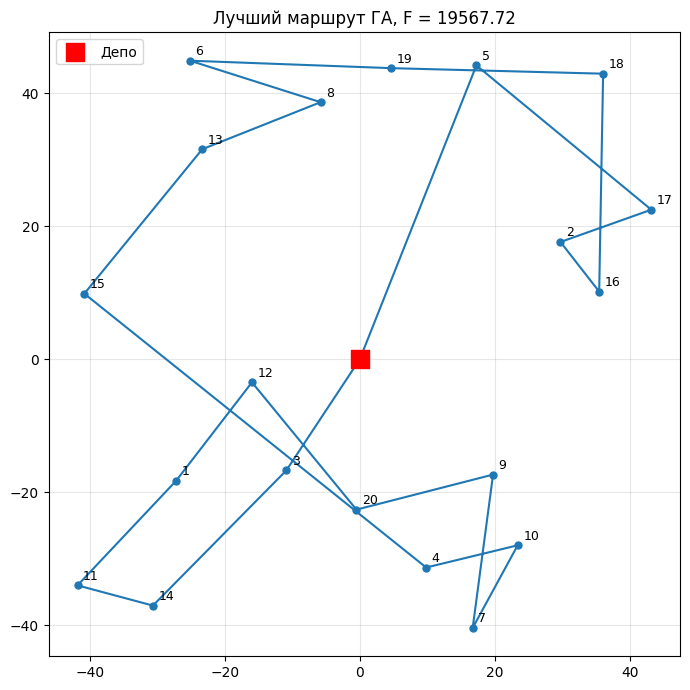

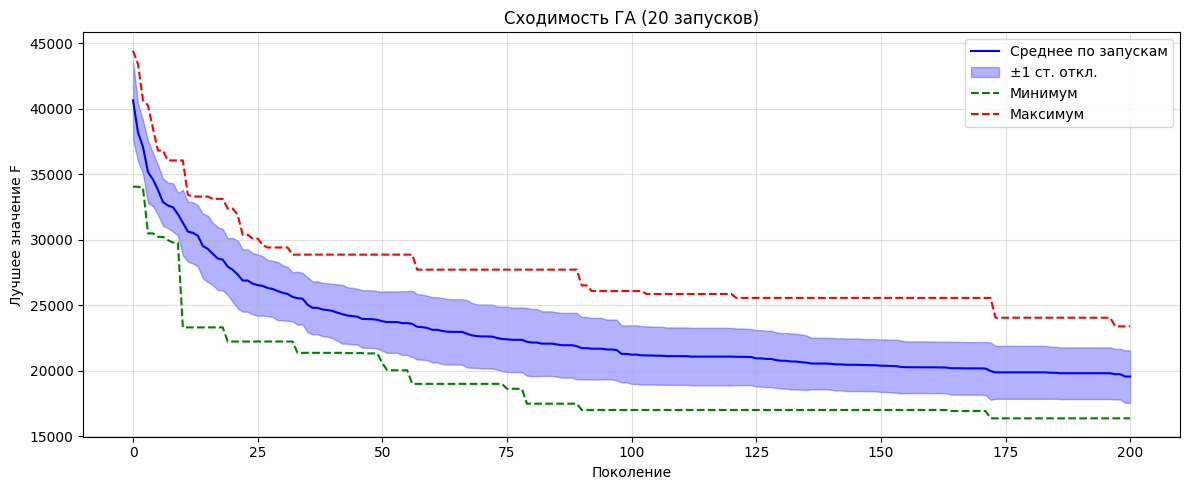

In [26]:

# Визуализация лучшего маршрута
def plot_route(perm, coords, title):
    pts = [0] + list(perm) + [0]
    xs = coords[pts, 0]; ys = coords[pts, 1]
    plt.figure(figsize=(7, 7))
    plt.plot(xs, ys, '-o', color='tab:blue', linewidth=1.5, markersize=5)
    plt.scatter(coords[0, 0], coords[0, 1], color='red', s=180,
                marker='s', zorder=5, label='Депо')
    for i, (x, y) in enumerate(coords[1:], start=1):
        plt.annotate(str(i), (x, y), textcoords='offset points',
                     xytext=(4, 4), fontsize=9)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('route_best.png', dpi=120)
    plt.show()

plot_route(best, COORDS, f"Лучший маршрут ГА, F = {best_f:.2f}")

# График сходимости
mean_hist = np.mean(histories, axis=0)
min_hist = np.min(histories, axis=0)
max_hist = np.max(histories, axis=0)
std_hist = np.std(histories, axis=0)

plt.figure(figsize=(12, 5))
plt.plot(mean_hist, label='Среднее по запускам', color='blue')
plt.fill_between(range(len(mean_hist)),
                 mean_hist - std_hist, mean_hist + std_hist,
                 alpha=0.3, color='blue', label='±1 ст. откл.')
plt.plot(min_hist, '--', label='Минимум', color='green')
plt.plot(max_hist, '--', label='Максимум', color='red')
plt.xlabel('Поколение')
plt.ylabel('Лучшее значение F')
plt.title('Сходимость ГА (20 запусков)')
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.savefig('convergence_lr2.png', dpi=120)
plt.show()

In [27]:
# Итоговая таблица лучшего решения
print(f"F = {best_f:.2f}")
print("Порядок посещения клиентов:")
print(best)

# Времена прибытия
t = 0.0
prev = 0
print(f"{'Шаг':<5}{'Клиент':<10}{'Прибытие':<12}{'Окно':<18}{'Опоздание':<10}")
for k, c in enumerate(best, 1):
    travel = DIST[prev, c]
    arrival = max(t + travel, E[c])
    lateness = max(0.0, arrival - L[c])
    window = f"[{E[c]:.1f}, {L[c]:.1f}]"
    print(f"{k:<5}{c:<10}{arrival:<12.1f}{window:<18}{lateness:<10.1f}")
    t = arrival + SERVICE[c]
    prev = c
back = DIST[prev, 0]
total_time = t + back
print()
print(f"Возврат в депо: {back:.1f}, итоговое время: {total_time:.1f}, лимит: {T_MAX}")
print(f"Превышение лимита: {max(0, total_time - T_MAX):.1f}")

F = 19567.72
Порядок посещения клиентов:
[np.int64(3), np.int64(14), np.int64(11), np.int64(1), np.int64(12), np.int64(20), np.int64(9), np.int64(7), np.int64(10), np.int64(4), np.int64(15), np.int64(13), np.int64(8), np.int64(6), np.int64(19), np.int64(18), np.int64(16), np.int64(2), np.int64(17), np.int64(5)]
Шаг  Клиент    Прибытие    Окно              Опоздание 
1    3         20.0        [16.7, 61.6]      0.0       
2    14        50.6        [36.7, 125.0]     0.0       
3    11        63.9        [51.7, 82.3]      0.0       
4    1         87.5        [15.3, 83.4]      4.1       
5    12        108.9       [10.7, 53.3]      55.6      
6    20        134.8       [32.2, 86.7]      48.1      
7    9         158.6       [50.3, 99.1]      59.5      
8    7         182.9       [29.7, 85.5]      97.5      
9    10        199.0       [10.8, 51.5]      147.5     
10   4         216.5       [15.6, 86.7]      129.8     
11   15        286.4       [12.5, 69.1]      217.4     
12   13        